# Quickstart guide for the tiled GEDI database on MAAP (R)

This quickstart guide is intended for R users who are already familiar with DuckDB, dplyr or SQL, and the principles of hive-partitioned parquet datasets; who are looking to get started with the tiled GEDI dataset. It is the R version of `quickstart.ipynb`. If that is not you, please check out `tiling_demo.ipynb`, which contains a more detailed tutorial.

Queries are shown both in SQL and in dplyr; use whichever you prefer.

## Setup

In an R workspace on MAAP:

```bash
$ git clone https://github.com/ameliaholcomb/gedi_tiler/
```

and open this notebook from `gedi_tiler/demos`.

The tiled GEDI database needs the R `duckdb` package version 1.5.2 or newer, and `dbplyr` 2.6.0 or newer. Check your versions below. If either is older, run the install cell once, then restart the kernel.

It is recommended to set up your MAAP node to have at least 16GB of RAM.

In [2]:
packageVersion("duckdb")
packageVersion("dbplyr")

[1] ‘1.5.6’

[1] ‘2.6.0’

In [ ]:
# Run once if the versions above are too old, then restart the kernel.
# install.packages(c("duckdb", "dbplyr"))

Installing packages into ‘/home/jovyan/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)



In [4]:
library(dplyr)
# Load the helper functions (init_duckdb, attach_ducklake, set_region, ...)
source("../gtiler/database/ducky.R")

# Set a temporary directory for DuckDB to fall over to disk
# if it runs out of memory. This must be a local directory, not an S3 path.
# Mounted S3 buckets on an ADE/Hub node are fine.
temp_dir <- "/tmp/duckdb"

# Create a connection to DuckDB with default settings and extensions enabled.
con <- init_duckdb(temp_dir = temp_dir)

# Attach to the GEDI database.
# This may take a few seconds.
attach_ducklake(
    con,
    bucket = "maap-ops-workspace",
    prefix = "shared/ameliah/tiled_gedi_v3",
    name = "gedi_dl"          # This is how you will refer to the full database in your queries
)

duckdb is storing downloaded extensions and secrets under ~/.duckdb:
ℹ /home/jovyan/.duckdb
This persists across sessions and is shared with the DuckDB CLI and other clients.
ℹ Run duckdb(shared_home = FALSE) to use a temporary directory instead.
ℹ See ?duckdb_storage for details and alternatives.


## TL;DR: Get data for a region

In [ ]:
# Download an example shapefile of the Mondah Forest in Gabon for the demo,
# or use your own local shapefile in the cells below.
system2("aws", c("s3", "cp", "s3://maap-ops-workspace/shared/ameliah/shapefiles/Mondah.gpkg", "/tmp/Mondah.gpkg"))

Reading layer `mondah' from data source `/tmp/Mondah.gpkg' using driver `GPKG'
Simple feature collection with 1 feature and 33 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: 9.307387 ymin: 0.5313453 xmax: 9.445467 ymax: 0.6442508
Geodetic CRS:  WGS 84


gedi_mondah: 1 tile



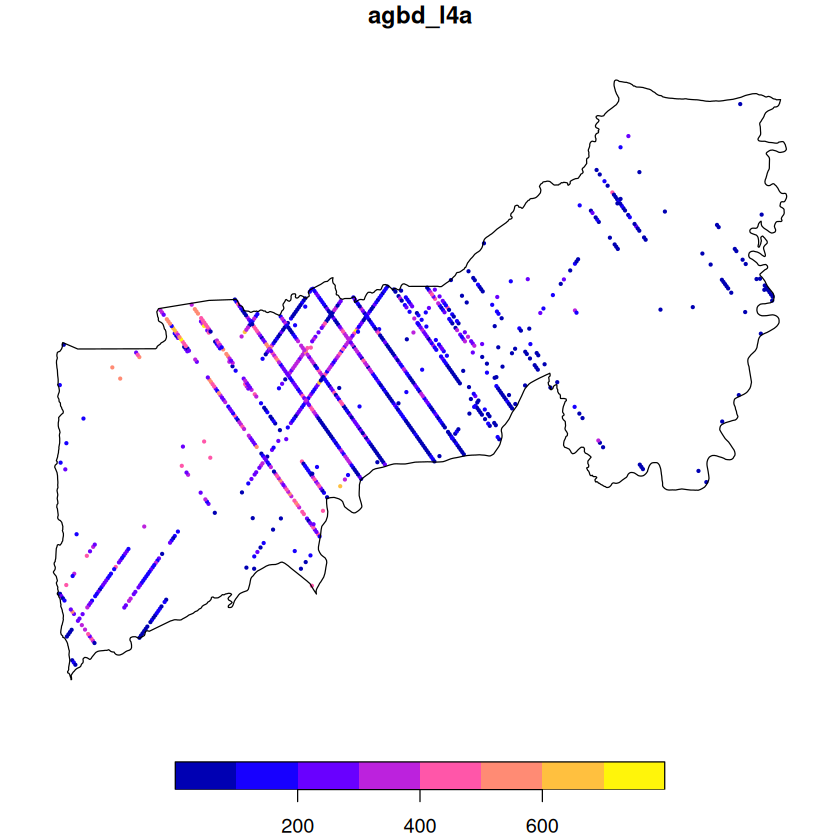

In [6]:
# Create a smaller regional database "view" on which spatial queries complete quickly
region <- st_read("/tmp/Mondah.gpkg")
set_region(
    con,                   # con: the DuckDB connection
    region,                # regions: an sf object, or a list of them (each may have its own CRS)
    name = "gedi_mondah"   # name: this is how you will refer to the regional database in your queries
)

# Load the region itself into DuckDB, so that queries can use its geometry.
mondah <- sf_to_duck(con, region, name = "mondah")

# Read the regional database view and filter to exactly our region with a join
in_mondah <- tbl(con, "gedi_mondah") |>
    # Can add other filters here
    filter(l4a_quality_flag_rel3_l4a == 1) |>
    inner_join(mondah, sql_on = "ST_Intersects(RHS.geom, LHS.geometry)") |>
    select(shot_number, absolute_time, agbd_l4a, pai_l2b, geometry)

# Convert to R spatial frame
in_mondah_sf <- duck_to_sf(in_mondah, geometry_columns = "geometry", crs = 4326)

# Plot the shots inside the region, colored by biomass
plot(in_mondah_sf["agbd_l4a"], pch = 20, cex = 0.5, extent = region, reset = FALSE)
plot(st_geometry(region), add = TRUE)

## Basic queries

In [9]:
# Try a sample query.
# tbl() runs the query lazily: printing it shows only the first rows,
# and nothing is loaded into R until you collect() it.
tbl(con, sql("
    SELECT shot_number, absolute_time, agbd_l4a, rh_l2a[99] AS rh98, geometry, geometry_6933
    FROM gedi_dl.data
    WHERE l4a_quality_flag_rel3_l4a = 1 AND year = 2025
"))

# A query:  ?? x 6
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number absolute_time       agbd_l4a  rh98 geometry   geometry_6933
       <int64> <dttm>                 <dbl> <dbl> <list>     <list>       
 1        3e17 2025-04-12 07:49:14    261.  27    <raw [21]> <raw [21]>   
 2        3e17 2025-04-12 07:49:14    317.  27.6  <raw [21]> <raw [21]>   
 3        3e17 2025-04-12 07:49:14    350.  28.9  <raw [21]> <raw [21]>   
 4        3e17 2025-04-12 07:49:14    339.  29.0  <raw [21]> <raw [21]>   
 5        3e17 2025-04-12 07:49:14     11.4  9.40 <raw [21]> <raw [21]>   
 6        3e17 2025-04-12 07:49:14    295.  27.8  <raw [21]> <raw [21]>   
 7        3e17 2025-04-12 07:49:14     41.9 11.8  <raw [21]> <raw [21]>   
 8        3e17 2025-04-12 07:49:14    231.  24.4  <raw [21]> <raw [21]>   
 9        3e17 2025-04-12 07:49:14    133.  19.6  <raw [21]> <raw [21]>   
10        3e17 2025-04-12 07:49:14    253.  27.3  <raw [21]> <raw 

In [10]:
# The same query in dplyr
gedi <- tbl(con, I("gedi_dl.data"))
gedi |>
    filter(l4a_quality_flag_rel3_l4a == 1, year == 2025) |>
    mutate(rh98 = rh_l2a[[99]]) |> 
    select(shot_number, absolute_time, agbd_l4a, rh98, geometry, geometry_6933)

# A query:  ?? x 6
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number absolute_time       agbd_l4a  rh98 geometry   geometry_6933
       <int64> <dttm>                 <dbl> <dbl> <list>     <list>       
 1        3e17 2025-06-15 01:42:45     289.  31.9 <raw [21]> <raw [21]>   
 2        3e17 2025-06-15 01:42:45     222.  28.6 <raw [21]> <raw [21]>   
 3        3e17 2025-06-15 01:42:45     183.  25.1 <raw [21]> <raw [21]>   
 4        3e17 2025-06-15 01:42:45     208.  28.5 <raw [21]> <raw [21]>   
 5        3e17 2025-06-15 01:42:45     161.  22.5 <raw [21]> <raw [21]>   
 6        3e17 2025-06-15 01:42:45     154.  27.3 <raw [21]> <raw [21]>   
 7        3e17 2025-06-15 01:42:45     176.  22.7 <raw [21]> <raw [21]>   
 8        3e17 2025-06-15 01:42:45     102.  17.7 <raw [21]> <raw [21]>   
 9        3e17 2025-06-15 01:42:45     151.  22.7 <raw [21]> <raw [21]>   
10        3e17 2025-06-15 01:42:45     103.  19.9 <raw [21]> <raw 

A few notes on columns in the v3 database:
- All science data columns are suffixed by the product from which they come, e.g. `agbd_l4a`
- The RH, RCH, and all other array columns in the GEDI data are maintained as arrays in the table. You can access individual values in your query using array syntax, but note that SQL and R are 1-indexed! 
    - RH_98 in SQL array syntax is `rh_l2a[99]`. 
    - In dplyr, use double brackets: `rh_l2a[[99]]`.
- If a column is present in multiple products, the column uses the suffix of the lowest product that contains it, e.g. `elev_lowestmode_l2a`
- A few special columns do not have suffixes:

| Column | Reason |
|---|---|
| `shot_number` | primary key joined on all products |
| `lon_lowestmode`; `lat_lowestmode` | matched across all products |
| `geometry` | derived column; not in original data |
| `geometry_6933` | derived column; not in original data |
| `ease_72km_x`;`ease_72_km_y` | derived columns; not in original data |
| `h3_03`; `h3_12` | derived columns; not in original data |
| `absolute_time` | derived column; not in original data |
| `tile_id` | partition column |
| `year` | partition column |

And a few notes for R:
- `shot_number` is too large to store exactly in an R number, so it comes back as `integer64` (from the `bit64` package). Query previews abbreviate it (e.g. `3e17`), but the values are exact, and collected results show every digit.
- Geometry columns show up as `<raw>` until you convert the result to `sf` (see the end of this notebook).
- `dbGetQuery(con, "SELECT ...")` runs a query and loads the whole result into an R data frame. Use it for small results, such as counts.

Most queries will work as you expect if you have used dplyr/SQL/DuckDB before. However, there is some special handling for spatial queries.

## Spatial queries

The tiled GEDI database is organized into 1º x 1º tiles covering the GEDI region, named by their top left corner in the format `'[N|S][##]_[E|W][###]'`. If you would like to read a 1 degree tile (for example, if your DPS jobs are distributed by 1ºx1º regions), this is very fast:

In [11]:
tbl(con, sql("
    SELECT shot_number, agbd_l4a, absolute_time, geometry, tile_id
    FROM gedi_dl.data
    WHERE
        tile_id = 'N07_W063'
        AND l4a_quality_flag_rel3_l4a = 1
"))

# A query:  ?? x 5
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number agbd_l4a absolute_time       geometry   tile_id 
       <int64>    <dbl> <dttm>              <list>     <chr>   
 1       1.e17    101.  2021-02-08 23:39:11 <raw [21]> N07_W063
 2       1.e17    109.  2021-02-08 23:39:11 <raw [21]> N07_W063
 3       1.e17    213.  2021-02-08 23:39:11 <raw [21]> N07_W063
 4       1.e17    183.  2021-02-08 23:39:11 <raw [21]> N07_W063
 5       1.e17    106.  2021-02-08 23:39:11 <raw [21]> N07_W063
 6       1.e17    112.  2021-02-08 23:39:11 <raw [21]> N07_W063
 7       1.e17     40.6 2021-02-08 23:39:11 <raw [21]> N07_W063
 8       1.e17    168.  2021-02-08 23:39:11 <raw [21]> N07_W063
 9       1.e17    158.  2021-02-08 23:39:11 <raw [21]> N07_W063
10       1.e17     69.1 2021-02-08 23:39:11 <raw [21]> N07_W063
# ℹ more rows

In [ ]:
# In dplyr
gedi <- tbl(con, I("gedi_dl.data"))
gedi |>
    filter(tile_id == "N07_W063", l4a_quality_flag_rel3_l4a == 1) |>
    select(shot_number, agbd_l4a, absolute_time, geometry, tile_id)

# A query:  ?? x 5
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number agbd_l4a absolute_time       geometry   tile_id 
       <int64>    <dbl> <dttm>              <list>     <chr>   
 1       2.e17     211. 2023-01-31 14:49:30 <raw [21]> N07_W063
 2       2.e17     217. 2023-01-31 14:49:30 <raw [21]> N07_W063
 3       2.e17     100. 2023-01-31 14:49:30 <raw [21]> N07_W063
 4       2.e17     150. 2023-01-31 14:49:30 <raw [21]> N07_W063
 5       2.e17     140. 2023-01-31 14:49:30 <raw [21]> N07_W063
 6       2.e17     265. 2023-01-31 14:49:29 <raw [21]> N07_W063
 7       2.e17     111. 2023-01-31 14:49:29 <raw [21]> N07_W063
 8       2.e17     195. 2023-01-31 14:49:29 <raw [21]> N07_W063
 9       2.e17     278. 2023-01-31 14:49:29 <raw [21]> N07_W063
10       2.e17     123. 2023-01-31 14:49:29 <raw [21]> N07_W063
# ℹ more rows

A bounding box is also fast using filters on the `lon_lowestmode` and `lat_lowestmode` columns:

In [ ]:
gedi <- tbl(con, I("gedi_dl.data"))
gedi |>
  filter(between(lon_lowestmode, -110.9, -109.5),
         between(lat_lowestmode, 29.6, 30.1)) |>
  filter(l4a_quality_flag_rel3_l4a == 1, rh_l2a[[99]] > 5) |>
  select(shot_number, agbd_l4a, absolute_time, geometry, tile_id)

# A query:  ?? x 5
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number agbd_l4a absolute_time       geometry   tile_id 
       <int64>    <dbl> <dttm>              <list>     <chr>   
 1        3e17    11.8  2024-10-15 21:03:32 <raw [21]> N31_W111
 2        3e17     8.61 2024-10-15 21:03:32 <raw [21]> N31_W111
 3        3e17     4.74 2024-10-15 21:03:32 <raw [21]> N31_W111
 4        3e17    15.3  2024-10-15 21:03:32 <raw [21]> N31_W111
 5        3e17    13.4  2024-10-15 21:03:32 <raw [21]> N31_W111
 6        3e17     8.97 2024-10-15 21:03:32 <raw [21]> N31_W111
 7        3e17    11.2  2024-10-15 21:03:32 <raw [21]> N31_W111
 8        3e17    16.1  2024-10-15 21:03:32 <raw [21]> N31_W111
 9        3e17    79.3  2024-10-15 21:03:32 <raw [21]> N31_W111
10        3e17    36.1  2024-10-15 21:03:32 <raw [21]> N31_W111
# ℹ more rows

For arbitrary shapes, though, we have to help the query planner use the spatial structure of the tiled GEDI database to run efficient spatial filters.[^1] Whenever you want to work with a specific region (or set of regions), use `set_region` to get a view of the full database restricted to only your region(s). Then select from the regional table name, rather than the full database (`gedi_dl.data`) used above.

[^1]: <small> For filters on simple datatypes (for example, filtering on `year` (integer), `absolute_time` (timestamp), or the raw `lon_lowestmode_l2a`/`lat_lowestmode_l2a` (float) columns), DuckDB's query planner will automatically prune the full database to only read relevant files for your query. However, the _spatial_ query planner is still in development, so we give it additional hints about how to efficiently read our database. </small>

In [ ]:
# Download an example shapefile of the Mondah Forest in Gabon for the demo,
# or use your own local shapefile in the cells below.
system2("aws", c("s3", "cp", "s3://maap-ops-workspace/shared/ameliah/shapefiles/Mondah.gpkg", "/tmp/Mondah.gpkg"))

In [21]:
region <- st_read("/tmp/Mondah.gpkg")
set_region(
    con,                   # con: the DuckDB connection
    region,                # regions: an sf object, or a list of them (each may have its own CRS)
    name = "gedi_mondah"   # name: this is how you will refer to the regional database in your queries
)

# set_region prints out the number of tiles that it restricted the database to.
# If this number is large (> 50 tiles) or if you are getting out-of-memory crashes, 
# consider asking #uwg for help on the best way to write your query!
# DuckDB is designed to handle very large datasets, but you may need more than a quickstart guide.

Reading layer `mondah' from data source `/tmp/Mondah.gpkg' using driver `GPKG'
Simple feature collection with 1 feature and 33 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: 9.307387 ymin: 0.5313453 xmax: 9.445467 ymax: 0.6442508
Geodetic CRS:  WGS 84


gedi_mondah: 1 tile



In [15]:
# Load the region itself into DuckDB, so that queries can use its geometry.
mondah <- sf_to_duck(con, region, name = "mondah")

# Now we can run exact spatial queries on this smaller spatial "view" of the larger table.
tbl(con, sql("
    SELECT shot_number, absolute_time, agbd_l4a, rh_l2a[99], geometry
    FROM
        gedi_mondah,
        mondah AS r
    WHERE
        ST_Intersects(r.geom, gedi_mondah.geometry)
        AND l4a_quality_flag_rel3_l4a = 1
"))

# A query:  ?? x 5
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
   shot_number absolute_time       agbd_l4a `rh_l2a[99]` geometry  
       <int64> <dttm>                 <dbl>        <dbl> <list>    
 1        3e16 2019-08-10 20:05:28   129.          30.5  <raw [21]>
 2        3e16 2019-08-10 20:05:28    11.9          7.86 <raw [21]>
 3        3e16 2019-08-10 20:05:28   178.          30.6  <raw [21]>
 4        3e16 2019-08-10 20:05:28    72.0         15.4  <raw [21]>
 5        3e16 2019-08-10 20:05:27    16.9         10.1  <raw [21]>
 6        3e16 2019-08-10 20:05:27    90.4         19.9  <raw [21]>
 7        3e16 2019-08-10 20:05:27    31.0         11.7  <raw [21]>
 8        3e16 2019-08-10 20:05:27   151.          28.0  <raw [21]>
 9        3e16 2019-08-10 20:05:27    41.8         13.9  <raw [21]>
10        3e16 2019-08-10 20:05:27     5.22         2.99 <raw [21]>
# ℹ more rows

In [8]:
# In dplyr, the spatial test is the join condition.
in_mondah <- tbl(con, "gedi_mondah") |>
    filter(l4a_quality_flag_rel3_l4a == 1) |>
    inner_join(mondah, sql_on = "ST_Intersects(RHS.geom, LHS.geometry)") |>
    select(shot_number, absolute_time, agbd_l4a, geometry)

in_mondah |> summarise(mean_agbd = mean(agbd_l4a, na.rm = TRUE), n = n())

# A query:  ?? x 2
# Database: DuckDB 1.5.6 [unknown@Linux 6.18.54-121.166.amzn2023.x86_64:R 4.5.1/:memory:]
  mean_agbd       n
      <dbl> <int64>
1      186.    1026

If your region is in a projected CRS (e.g. UTM), transform the GEDI points into the region's CRS, rather than the region into lon/lat:

```sql
ST_Intersects(ST_Transform(gedi_region.geometry, 'OGC:CRS84', ST_CRS(r.geom), always_xy := true), r.geom)
```

For convenience, the GEDI database already has a column called `geometry_6933` in the EASE-2.0 Grid EPSG:6933 projection.

## Convert to an R object (sf)

Simple feature collection with 1026 features and 3 fields
Geometry type: POINT
Dimension:     XY
Bounding box:  xmin: 9.308591 ymin: 0.5341653 xmax: 9.442827 ymax: 0.6397283
Geodetic CRS:  WGS 84
# A tibble: 1,026 × 4
   shot_number absolute_time       agbd_l4a             geometry
       <int64> <dttm>                 <dbl>          <POINT [°]>
 1        6e16 2020-01-20 15:40:31   214.    (9.415664 0.633698)
 2        6e16 2020-01-20 15:40:31     8.48 (9.417737 0.6269155)
 3        6e16 2020-01-20 15:40:31   133.   (9.414185 0.6315928)
 4        6e16 2020-01-20 15:40:30    81.9  (9.373947 0.5954394)
 5        6e16 2020-01-20 15:40:30   163.   (9.365039 0.5827928)
 6        6e16 2020-01-20 15:40:30    16.1  (9.372374 0.5833901)
 7        6e16 2020-01-20 15:40:30   174.    (9.37386 0.5855003)
 8        6e16 2020-01-20 15:40:30   665.   (9.361404 0.5677767)
 9        6e16 2020-01-20 15:40:30   340.   (9.362286 0.5690396)
10        6e16 2020-01-20 15:40:30   106.   (9.362873 0.5698815)
# 

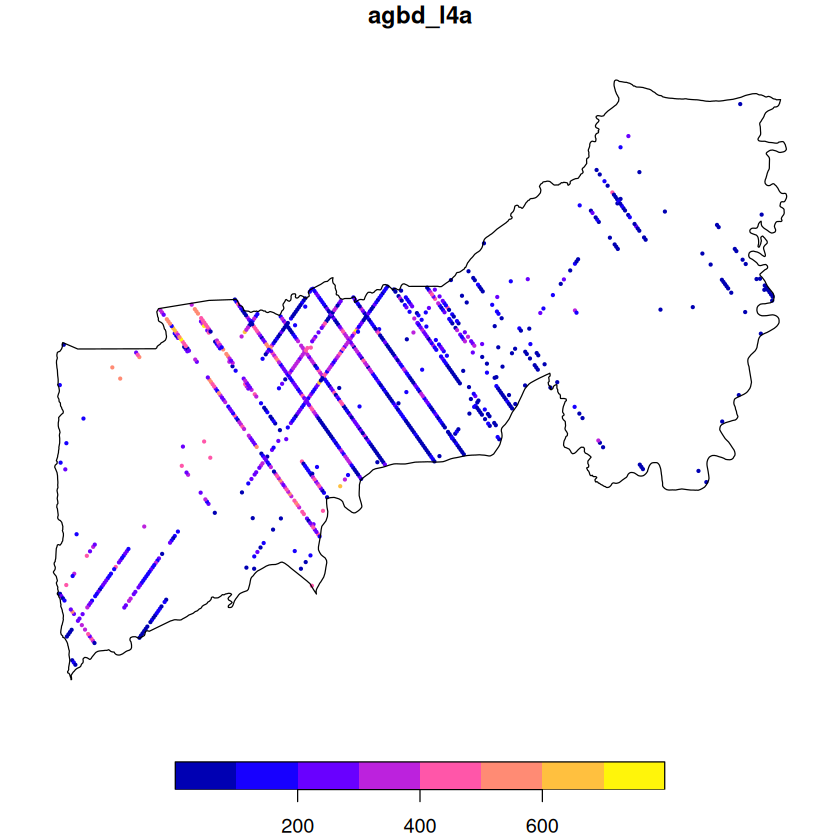

In [ ]:
# DuckDB table to sf data frame
#   - geometry_columns lists the columns containing a geometry type.
#   - sf requires a single primary geometry column; the primary column will
#       be the first geometry column in the list.
#   - crs is the CRS of the geometry columns
in_mondah_sf <- duck_to_sf(in_mondah, geometry_columns = "geometry", crs = 4326)
print(in_mondah_sf)

# Plot the shots inside the region, colored by biomass
plot(in_mondah_sf["agbd_l4a"], pch = 20, cex = 0.5, extent = region, reset = FALSE)
plot(st_geometry(region), add = TRUE)

In [ ]:
# Without geometry, you can just use collect() to return a plain R data frame (tibble).
in_mondah |> select(-geometry) |> collect()

shot_number,absolute_time,agbd_l4a
<int64>,<dttm>,<dbl>
62670800200060331,2020-01-20 15:40:31,213.736298
62671100200056434,2020-01-20 15:40:31,8.483961
62670800200060326,2020-01-20 15:40:31,133.330994
62670500200056359,2020-01-20 15:40:30,81.926178
62670500200056329,2020-01-20 15:40:30,163.230103
62670600200282332,2020-01-20 15:40:30,16.130705
62670600200282337,2020-01-20 15:40:30,173.780212
62670600200282295,2020-01-20 15:40:30,664.972900
62670600200282298,2020-01-20 15:40:30,340.489716
